# Week 1 — Foundations for Neural NLP

**CSS371: Natural Language Processing**  

This notebook introduces the mathematical operations that appear repeatedly in neural language models: vectors, dot products, matrix multiplication, logits, softmax, cross-entropy, and sampling. The goal is not to cover linear algebra in full, but to build an operational understanding that we will reuse when studying embeddings, attention, and language-model training.

## Objectives

1. Connect basic linear-algebra operations to neural NLP computations.
2. Implement important operations manually before using library functions.
3. Interpret logits as model scores and convert them into probabilities.
4. Relate cross-entropy to next-token prediction.
5. Explore how sampling changes model outputs.

## Learning outcomes

By the end of this class, you should be able to:

- compute and interpret a dot product;
- predict the shape of a matrix multiplication result;
- implement a numerically stable softmax function;
- compute the negative log-likelihood of a target token;
- explain why minimizing cross-entropy increases the target token's probability; and
- distinguish greedy decoding from probabilistic sampling.

## Class roadmap

| Segment | Topic |
|---|---:|
| Step 1 | Vectors and tensor shapes |
| Step 2 | Dot products as similarity and neuron scores |
| Step 3 | Matrix multiplication as batched dot products |
| Step 4 | From hidden states to logits |
| Step 5 | Softmax and numerical stability |
| Step 6 | Entropy, cross-entropy, and token loss |
| Step 7 | Greedy decoding, sampling, and temperature |


In [1]:
# Environment and reproducibility
import sys
import numpy as np
import matplotlib.pyplot as plt
import torch

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"Python:     {sys.version.split()[0]}")
print(f"NumPy:      {np.__version__}")
print(f"PyTorch:    {torch.__version__}")
print(f"Device:     {'cuda' if torch.cuda.is_available() else 'cpu'}")

Python:     3.12.13
NumPy:      2.0.2
PyTorch:    2.11.0+cpu
Device:     cpu


## Step 1 — Vectors and tensor shapes

A neural language model represents information using arrays of numbers. A **scalar** has no axis, a **vector** has one axis, a **matrix** has two axes, and a higher-dimensional array is commonly called a **tensor**.

For a batch of token representations, a common shape is

$$X \in \mathbb{R}^{B \times T \times D},$$

where $B$ is batch size, $T$ is sequence length, and $D$ is embedding dimension.

**Before running the next cell:** predict the shape and number of values in `token_states`.

In [3]:
batch_size, sequence_length, embedding_dim = 2, 4, 3
token_states = torch.arange(
    batch_size * sequence_length * embedding_dim, dtype=torch.float32
).reshape(batch_size, sequence_length, embedding_dim)

print('Shape:', token_states.shape)
print('Number of values:', token_states.numel())
print('First token representation:', token_states[0])

Shape: torch.Size([2, 4, 3])
Number of values: 24
First token representation: tensor([[ 0.,  1.,  2.],
        [ 3.,  4.,  5.],
        [ 6.,  7.,  8.],
        [ 9., 10., 11.]])


### Key result — Step 1

- **Observation:** The tensor has shape `(2, 4, 3)` and contains $2 \times 4 \times 3=24$ values.
- **Interpretation:** Every token is represented by a vector of length $D=3$; tokens are organized by sequence and batch.
- **Limitation:** Axis conventions can differ across libraries. Never infer axis meaning from shape alone—check the documentation or variable definitions.

## Step 2 — Dot products: one operation, two interpretations

For two vectors $\mathbf{x},\mathbf{w}\in\mathbb{R}^{D}$, their dot product is

$$\mathbf{x}\cdot\mathbf{w}=\sum_{i=1}^{D}x_iw_i. $$

In a neuron, this produces a weighted score. When vectors are normalized, the same operation measures cosine similarity:

$$\cos(\theta)=\frac{\mathbf{x}\cdot\mathbf{w}}{\|\mathbf{x}\|_2\|\mathbf{w}\|_2}. $$

In [6]:
activation = torch.tensor([1.0, 3.0, -3.0, 4.0, 0.0])
weight = torch.tensor([0.3, -0.2, -0.1, 0.4, 0.5])

manual_score = torch.sum(activation * weight)
library_score = torch.dot(activation, weight)
cosine_similarity = library_score / (torch.linalg.vector_norm(activation) * torch.linalg.vector_norm(weight))

print(f'Manual dot product: {manual_score:.4f}')
print(f'torch.dot result:   {library_score:.4f}')
print(f'Cosine similarity:  {cosine_similarity:.4f}')
assert torch.allclose(manual_score, library_score)

Manual dot product: 1.6000
torch.dot result:   1.6000
Cosine similarity:  0.3647


### Key result — Step 2

- **Observation:** Element-wise multiplication followed by summation gives the same result as `torch.dot`.
- **Interpretation:** A dot product is a weighted combination. Its magnitude also reflects vector length, while cosine similarity removes the effect of length.
- **Limitation:** A high cosine similarity in an embedding space suggests geometric alignment; it does not by itself prove that two words have identical meanings.

## Step 3 — Matrix multiplication: many dot products at once

Let $X\in\mathbb{R}^{N\times D}$ contain $N$ input vectors and $W\in\mathbb{R}^{D\times K}$ contain $K$ output directions. Then

$$Y=XW, \qquad Y\in\mathbb{R}^{N\times K},$$

and every entry is a dot product:

$$Y_{n,k}=\sum_{d=1}^{D}X_{n,d}W_{d,k}. $$

This is the core operation in linear layers, attention projections, and vocabulary prediction.

In [7]:
X = torch.tensor([[1.0, 2.0, 0.0],
                  [0.0, 1.0, 3.0]])       # [N=2, D=3]
W = torch.tensor([[ 0.2,  0.5, -0.1,  0.0],
                  [ 0.3, -0.4,  0.8,  0.1],
                  [-0.5,  0.2,  0.4,  0.9]])  # [D=3, K=4]

Y = X @ W
manual_y_0_2 = torch.dot(X[0], W[:, 2])

print('X shape:', tuple(X.shape))
print('W shape:', tuple(W.shape))
print('Y shape:', tuple(Y.shape))
print('\nY =\n', Y)
print(f'\nManual Y[0, 2]: {manual_y_0_2:.4f}')
print(f'Matrix Y[0, 2]: {Y[0, 2]:.4f}')
assert torch.allclose(manual_y_0_2, Y[0, 2])

X shape: (2, 3)
W shape: (3, 4)
Y shape: (2, 4)

Y =
 tensor([[ 0.8000, -0.3000,  1.5000,  0.2000],
        [-1.2000,  0.2000,  2.0000,  2.8000]])

Manual Y[0, 2]: 1.5000
Matrix Y[0, 2]: 1.5000


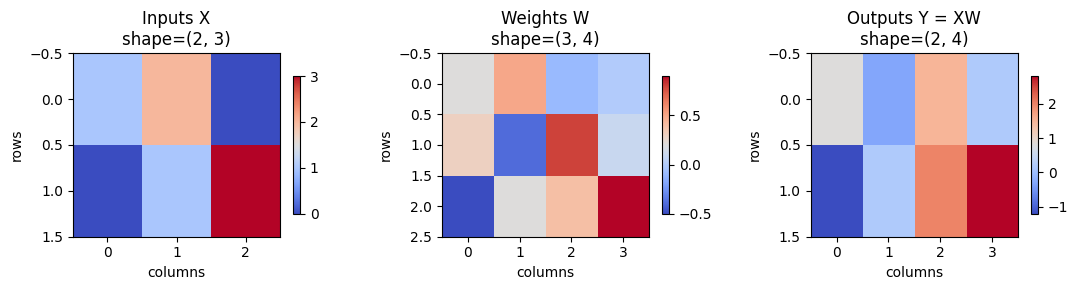

In [ ]:
# Visualize the matrices as heatmaps. The figure is generated locally.
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, matrix, title in zip(axes, [X, W, Y], ['Inputs X', 'Weights W', 'Outputs Y = XW']):
    image = ax.imshow(matrix.numpy(), cmap='coolwarm', aspect='auto')
    ax.set_title(f'{title}\nshape={tuple(matrix.shape)}')
    ax.set_xlabel('columns')
    ax.set_ylabel('rows')
    fig.colorbar(image, ax=ax, shrink=0.75)
plt.tight_layout()
plt.show()

### Key result — Step 3

- **Observation:** Multiplying `[N, D] @ [D, K]` produces `[N, K]`; the shared dimension $D$ is summed out.
- **Interpretation:** Matrix multiplication efficiently computes every input–output dot product.
- **Limitation:** Compatible shapes guarantee that the operation runs, not that the axes have the intended semantic meaning.

> **Checkpoint:** What shape would result from `[batch, tokens, D] @ [D, vocabulary]`?

## Step 4 — From a hidden state to vocabulary logits

A language model produces a hidden vector $\mathbf{h}\in\mathbb{R}^{D}$. An output matrix $W_{\text{vocab}}\in\mathbb{R}^{D\times V}$ maps it to one score per vocabulary item:

$$\mathbf{z}=\mathbf{h}W_{\text{vocab}}+\mathbf{b}, \qquad \mathbf{z}\in\mathbb{R}^{V}. $$

The values $\mathbf{z}$ are called **logits**. Logits are unrestricted scores—not probabilities.

In [8]:
vocabulary = ['the', 'cat', 'sat', 'runs', '<eos>']
hidden_state = torch.tensor([0.6, -0.2, 0.8])
W_vocab = torch.tensor([[ 0.3,  0.8, -0.2,  0.1, -0.5],
                        [-0.1,  0.2,  0.6, -0.3,  0.4],
                        [ 0.5, -0.4,  0.9,  0.2,  0.1]])
bias = torch.tensor([0.0, 0.1, -0.1, 0.0, 0.05])

logits = hidden_state @ W_vocab + bias
for token, score in zip(vocabulary, logits):
    print(f'{token:>5}: {score.item(): .3f}')

  the:  0.600
  cat:  0.220
  sat:  0.380
 runs:  0.280
<eos>: -0.250


### Key result — Step 4

- **Observation:** The output contains exactly one score for each vocabulary item. Scores may be negative and do not sum to one.
- **Interpretation:** Relative logits express model preference before probability normalization.
- **Limitation:** A top-scoring token is only the model's preferred continuation under the current context and parameters; it is not necessarily factual or grammatically valid.

## Step 5 — Softmax and numerical stability

Softmax converts $V$ logits into a categorical probability distribution:

$$p_i=\operatorname{softmax}(z_i)=\frac{e^{z_i}}{\sum_{j=1}^{V}e^{z_j}}. $$

Because exponentials can overflow, implementations subtract the largest logit. This does not change the result mathematically:

$$p_i=\frac{e^{z_i-m}}{\sum_j e^{z_j-m}}, \qquad m=\max_j z_j. $$

In [9]:
def stable_softmax(values: torch.Tensor, dim: int = -1) -> torch.Tensor:
    shifted = values - values.max(dim=dim, keepdim=True).values
    exponentials = torch.exp(shifted)
    return exponentials / exponentials.sum(dim=dim, keepdim=True)

probabilities = stable_softmax(logits)
torch_probabilities = torch.softmax(logits, dim=-1)

for token, probability in zip(vocabulary, probabilities):
    print(f'{token:>5}: {probability.item():.3f}')
print(f'Probability sum: {probabilities.sum().item():.6f}')
assert torch.allclose(probabilities, torch_probabilities)

  the: 0.275
  cat: 0.188
  sat: 0.220
 runs: 0.199
<eos>: 0.117
Probability sum: 1.000000


In [13]:
# Demonstrate why the stable form matters.
large_logits = torch.tensor([100.0, 101.0, 102.0])
naive = torch.exp(large_logits) / torch.exp(large_logits).sum()
stable = stable_softmax(large_logits)
print('Naive softmax: ', naive)
print('Stable softmax:', stable)

Naive softmax:  tensor([nan, nan, nan])
Stable softmax: tensor([0.0900, 0.2447, 0.6652])


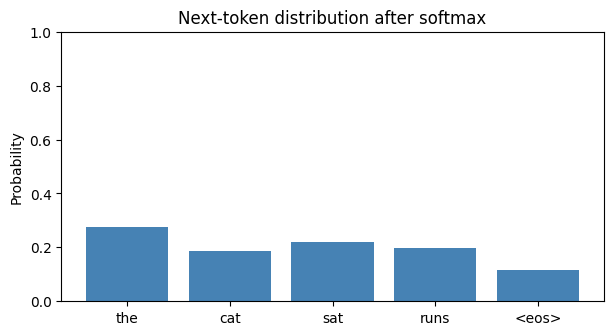

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(vocabulary, probabilities.numpy(), color='steelblue')
ax.set(ylabel='Probability', title='Next-token distribution after softmax', ylim=(0, 1))
plt.show()

### Key result — Step 5

- **Observation:** Stable softmax produces finite probabilities that sum to one; the naive calculation produces invalid values for very large logits.
- **Interpretation:** Softmax preserves logit ranking but turns score differences into probability ratios. Subtracting a constant from all logits does not change those ratios.
- **Limitation:** Softmax probabilities need not be calibrated. A value of 0.90 does not automatically mean that the prediction is correct 90% of the time.

## Step 6 — Cross-entropy and next-token loss

If the correct next token has index $y$, its one-hot target distribution is $q$. Categorical cross-entropy is

$$H(q,p)=-\sum_{i=1}^{V}q_i\log p_i=-\log p_y. $$

Thus, assigning a larger probability to the correct token produces a smaller loss. In practice, `torch.nn.functional.cross_entropy` accepts raw logits and performs log-softmax internally for numerical stability.

In [15]:
import torch.nn.functional as F

target_token = 'sat'
target_index = vocabulary.index(target_token)
manual_nll = -torch.log(probabilities[target_index])
library_loss = F.cross_entropy(logits.unsqueeze(0), torch.tensor([target_index]))

print(f'Target token: {target_token!r}')
print(f'Target probability: {probabilities[target_index].item():.4f}')
print(f'Manual negative log-likelihood: {manual_nll.item():.4f}')
print(f'PyTorch cross-entropy:          {library_loss.item():.4f}')
assert torch.allclose(manual_nll, library_loss)

Target token: 'sat'
Target probability: 0.2205
Manual negative log-likelihood: 1.5120
PyTorch cross-entropy:          1.5120


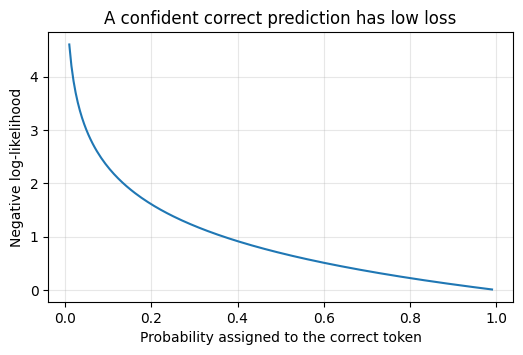

In [16]:
# How does target probability affect loss?
target_probabilities = torch.linspace(0.01, 0.99, 200)
losses = -torch.log(target_probabilities)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(target_probabilities, losses)
ax.set(xlabel='Probability assigned to the correct token',
       ylabel='Negative log-likelihood',
       title='A confident correct prediction has low loss')
ax.grid(alpha=0.3)
plt.show()

### Key result — Step 6

- **Observation:** Manual $-\log p_y$ and PyTorch cross-entropy agree. The loss approaches zero as the target probability approaches one.
- **Interpretation:** Minimizing cross-entropy encourages the model to increase the correct token's logit relative to competing logits.
- **Limitation:** Low training loss does not guarantee generalization, truthfulness, or useful generated text. Evaluation must use unseen data and task-appropriate measures.

## Step 7 — Greedy decoding, sampling, and temperature

Greedy decoding selects $\arg\max_i z_i$. Sampling instead draws an index according to the softmax distribution. Temperature $\tau>0$ adjusts its sharpness:

$$p_i(\tau)=\operatorname{softmax}\left(\frac{z_i}{\tau}\right). $$

A smaller temperature sharpens the distribution; a larger temperature flattens it. Temperature does not add knowledge—it only changes how existing model scores are used.

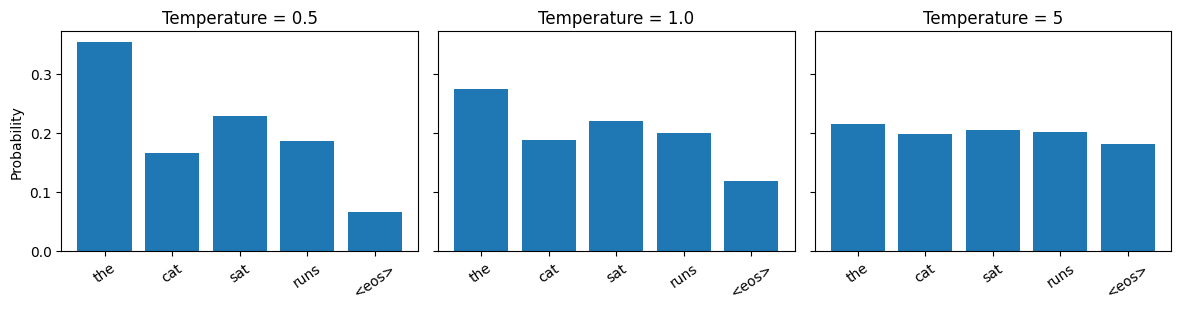

In [17]:
temperatures = [0.5, 1.0, 5]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)

for ax, temperature in zip(axes, temperatures):
    probs_t = torch.softmax(logits / temperature, dim=-1)
    ax.bar(vocabulary, probs_t.numpy())
    ax.set_title(f'Temperature = {temperature}')
    ax.tick_params(axis='x', rotation=35)
axes[0].set_ylabel('Probability')
plt.tight_layout()
plt.show()

In [18]:
torch.manual_seed(SEED)
greedy_index = torch.argmax(logits).item()
sample_count = 1_000
sampled_indices = torch.multinomial(probabilities, sample_count, replacement=True)
empirical_frequencies = torch.bincount(sampled_indices, minlength=len(vocabulary)) / sample_count

print('Greedy token:', vocabulary[greedy_index])
print('\nToken       theoretical   empirical')
for token, theoretical, empirical in zip(vocabulary, probabilities, empirical_frequencies):
    print(f'{token:>5}       {theoretical.item():.3f}         {empirical.item():.3f}')

Greedy token: the

Token       theoretical   empirical
  the       0.275         0.291
  cat       0.188         0.175
  sat       0.220         0.254
 runs       0.199         0.161
<eos>       0.117         0.119


### Key result — Step 7

- **Observation:** Greedy decoding always returns the top-ranked token, whereas repeated samples approximately follow the theoretical probabilities.
- **Interpretation:** Temperature controls diversity by changing distribution sharpness before sampling.
- **Limitation:** Very low temperature can make output repetitive; very high temperature can select implausible tokens. The best setting depends on the model and task.

## Guided practice

Complete these tasks by modifying copies of the relevant cells.

1. Change `hidden_state` and identify which vocabulary logit changes most. Explain your answer using the columns of `W_vocab`.
2. Verify experimentally that adding the same constant to every logit does not change softmax probabilities.
3. Calculate the loss when each vocabulary item is treated as the target. Which target gives the smallest loss, and why?
4. Compare 1,000 samples at temperatures 0.5 and 2.0. Which distribution has higher empirical entropy?

### Optional challenge

Implement a function `token_loss(hidden_state, W_vocab, bias, target_index)` without calling `torch.softmax` or `F.cross_entropy`. Use the stable softmax idea, and compare the result with PyTorch.

In [ ]:
# Practice workspace — keep experiments small and explain each result.
# YOUR CODE HERE


## Concept check

Answer without running code first.

1. If `X.shape == (8, 12, 64)` and `W.shape == (64, 5000)`, what is the shape of `X @ W`?
2. Why are logits not probabilities?
3. Why does stable softmax subtract the maximum logit?
4. What happens to cross-entropy when the target probability decreases toward zero?
5. How do greedy decoding and sampling differ?

<details>
<summary>Suggested answers</summary>

1. `(8, 12, 5000)`; the final dimension 64 is contracted.
2. They are unrestricted real-valued scores and need not be non-negative or sum to one.
3. It prevents exponential overflow while leaving the softmax distribution unchanged.
4. The loss $-\log p_y$ grows toward infinity.
5. Greedy decoding takes the maximum-score token deterministically; sampling draws according to a probability distribution.

</details>

## Summary and key takeaways

1. Neural NLP systems organize token representations as tensors; axis meaning matters as much as shape.
2. A dot product produces a weighted score, and matrix multiplication computes many dot products efficiently.
3. A vocabulary projection converts hidden states into logits—one unrestricted score per token.
4. Stable softmax converts logits into probabilities without numerical overflow.
5. For a one-hot target, cross-entropy equals the negative log-probability of the correct token.
6. Decoding strategy changes generated output even when model logits remain fixed.

### Connection to upcoming classes

These operations will reappear in embedding lookup, attention scores, feed-forward layers, vocabulary prediction, and model training.